# Modelo de regresión logística multinomial

**Proyecto 2 — Predicción de preferencias humanas en Chatbot Arena**  
**CC3084 Data Science | Universidad del Valle de Guatemala | 2026**

Este notebook implementa la contribución individual de regresión logística. Continúa el EDA previo: no repite la limpieza, no altera `data/splits.csv` y reserva test para la evaluación final. El código reutilizable vive en `src/logreg_model.py`.

## 1. Pregunta, alcance y evolución de la decisión

**Pregunta específica:** ¿hasta qué punto las longitudes de las respuestas, sus diferencias, el número de turnos y la identidad de los modelos permiten predecir si gana A, gana B o hay empate?

La revisión bibliográfica preliminar consideró regresión logística, Random Forest, XGBoost, SVM, MLP, Transformers y Bradley–Terry–Davidson. La especificación técnica posterior asignó cuatro contribuciones: regresión logística, XGBoost, embeddings y DeBERTa. Se sigue este contrato más reciente y aquí no se implementan los otros algoritmos. La investigación trata preferencias humanas de Chatbot Arena; el encabezado administrativo sobre compradores recurrentes no corresponde al dataset utilizado.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import features, load, splits
from src.logreg_model import (
    C_GRID, NUMERIC_FEATURES, build_pipeline, predict_proba,
    predict_single, prepare_xy, run_full_experiment,
)

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda value: f'{value:.6f}')
print(f'Raíz del proyecto: {ROOT}')

Raíz del proyecto: C:\Users\miafu\Downloads\CC3084-PRY2


## 2. Hipótesis

- **H1:** la longitud contiene información para distinguir victorias A/B.
- **H2:** agregar `model_a` y `model_b` mejora la calidad de las probabilidades.
- **H3:** el empate será más difícil de identificar o mostrará errores distintos.
- **H4:** el clasificador puede ser sensible al intercambio A/B aun sin un sesgo descriptivo global fuerte.
- **H5:** las variables tabulares pueden formar una referencia útil, sin capturar necesariamente toda la semántica.

Los antecedentes 61.63 %, +0.177 y −0.179 pertenecen al EDA y no se presentan como resultados del modelo.

In [2]:
train = load.load_split('train')
val = load.load_split('val')
test = load.load_split('test')
clean = load.load_train_clean()
partition_summary = splits.check_splits(clean, load.load_splits())
display(partition_summary)
print(f'train={len(train):,}, val={len(val):,}, test={len(test):,}')
assert len(train) + len(val) + len(test) == 57_406

,n,% total,% model_a gana,% model_b gana,% empate
split,,,,,
train,40180,69.990000,34.930000,34.220000,30.850000
val,8613,15.000000,34.950000,34.200000,30.850000
test,8613,15.000000,34.940000,34.220000,30.850000


train=40,180, val=8,613, test=8,613


## 3. Variables, pipelines y prueba inicial

La Variante A usa trece variables numéricas construidas por `features.build_base_features`. La Variante B añade las identidades de ambos modelos. `StandardScaler` y `OneHotEncoder(handle_unknown='ignore')` se ajustan dentro del pipeline, solo sobre entrenamiento. `lbfgs` optimiza la pérdida multinomial con L2. En scikit-learn 1.8 no se pasa el parámetro eliminado `multi_class` ni el deprecado `penalty`; `l1_ratio=0` conserva L2.

In [3]:
smoke = train.sample(900, random_state=42)
X_smoke, y_smoke = prepare_xy(smoke)
assert not {'winner', 'winner_model_a', 'winner_model_b', 'winner_tie'} & set(X_smoke.columns)
smoke_pipeline = build_pipeline(include_model_identity=True, c_value=0.1, max_iter=1_000)
smoke_pipeline.fit(X_smoke, y_smoke)
smoke_probabilities = predict_proba(smoke_pipeline, smoke.head(20))
assert smoke_probabilities.shape == (20, 3)
assert (abs(smoke_probabilities.sum(axis=1) - 1) < 1e-10).all()
print('Prueba inicial superada; orden de clases:', smoke_pipeline.named_steps['classifier'].classes_)

Prueba inicial superada; orden de clases: [0 1 2]


## 4. Entrenamiento completo y búsqueda de C

`run_full_experiment` evalúa `C = [0.01, 0.1, 1, 10]` con cinco folds de `StratifiedGroupKFold` sobre entrenamiento, agrupados por `prompt_text`. Luego reajusta ambas variantes, compara en validación, fija B antes de acceder evaluativamente a test y genera CSV, JSON, pipeline y figuras. Para reproducir todo desde cero, use `RUN_TRAINING = True`; si ya existen artefactos verificados, el notebook los carga para no repetir 40 ajustes innecesariamente.

In [4]:
RUN_TRAINING = False
metrics_path = ROOT / 'results' / 'metrics' / 'logreg.json'
if RUN_TRAINING or not metrics_path.exists():
    metrics = run_full_experiment(root=ROOT, c_grid=C_GRID, n_splits=5, max_iter=1_000)
else:
    with metrics_path.open(encoding='utf-8') as file:
        metrics = json.load(file)
print('Artefactos cargados. scikit-learn:', metrics['versions']['scikit_learn'])
print('Mejor C A:', metrics['chosen_hyperparameters']['variant_a']['C'])
print('Mejor C B:', metrics['chosen_hyperparameters']['variant_b']['C'])
print('Advertencias:', metrics['convergence'])

Artefactos cargados. scikit-learn: 1.8.0
Mejor C A: 0.01
Mejor C B: 1.0
Advertencias: {'variant_a_cv': [], 'variant_b_cv': [], 'variant_a_final': [], 'variant_b_final': []}


,Variante,C,Log loss medio,Desviación,Advertencias
0,Variante A,0.010000,1.066132,0.003288,0
1,Variante A,0.100000,1.066179,0.003390,0
2,Variante A,1.000000,1.066189,0.003407,0
3,Variante A,10.000000,1.066190,0.003409,0
4,Variante B,0.010000,1.034406,0.001883,0
5,Variante B,0.100000,1.026318,0.000989,0
6,Variante B,1.000000,1.026131,0.001187,0
7,Variante B,10.000000,1.026225,0.001234,0


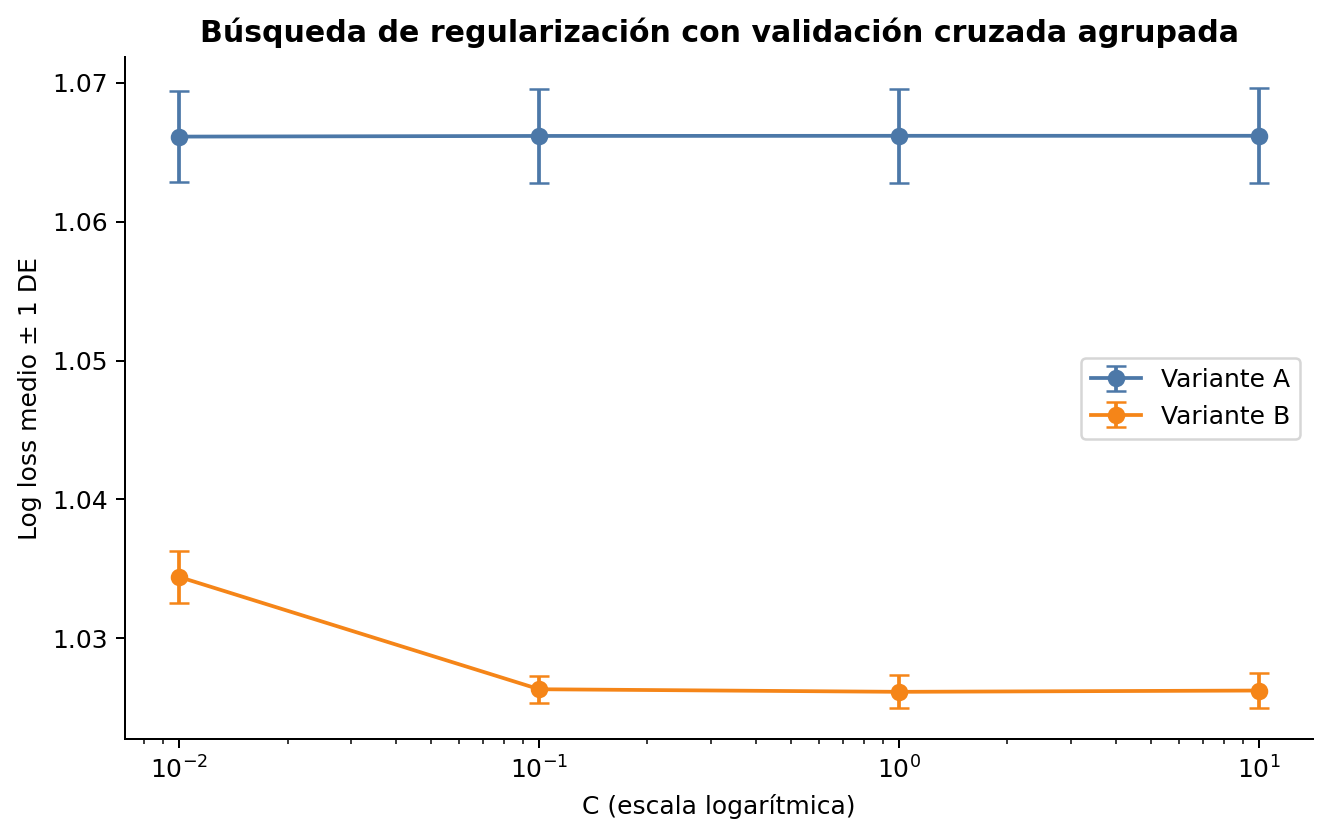

In [5]:
cv_rows = []
for key, label in [('variant_a', 'Variante A'), ('variant_b', 'Variante B')]:
    for row in metrics['hyperparameter_search'][key]['results']:
        cv_rows.append({
            'Variante': label, 'C': row['C'],
            'Log loss medio': row['mean_log_loss'],
            'Desviación': row['std_log_loss'],
            'Advertencias': row['convergence_warning_count'],
        })
display(pd.DataFrame(cv_rows))
display(Image(filename=ROOT / 'docs/figures/logreg_busqueda_c.png'))

## 5. Baseline, validación y prueba final

El baseline repite las proporciones de entrenamiento. La tabla usa el tiempo total de selección y ajuste final; la inferencia se mide sobre cada partición completa. Test se evaluó solo después de fijar la Variante B.

VALIDACIÓN


,Modelo,Log loss,F1 macro,Accuracy,Tiempo de entrenamiento,Tiempo de inferencia
0,Baseline,1.097165,0.172646,0.349472,0.000100,0.000493
1,Variante A,1.065427,0.422762,0.450714,2.851354,0.004557
2,Variante B,1.027420,0.451800,0.480553,12.161736,0.014684


TEST FINAL


,Modelo,Log loss,F1 macro,Accuracy,Tiempo de entrenamiento,Tiempo de inferencia
0,Baseline,1.097168,0.172604,0.349356,0.000100,0.000066
1,Variante A,1.065373,0.414086,0.439684,2.851354,0.004393
2,Variante B,1.025277,0.450521,0.477650,12.161736,0.014569


Cambio B − A en validación: {'log_loss': -0.0380075931917192, 'f1_macro': 0.029037815845667392, 'accuracy': 0.029838616045512578}


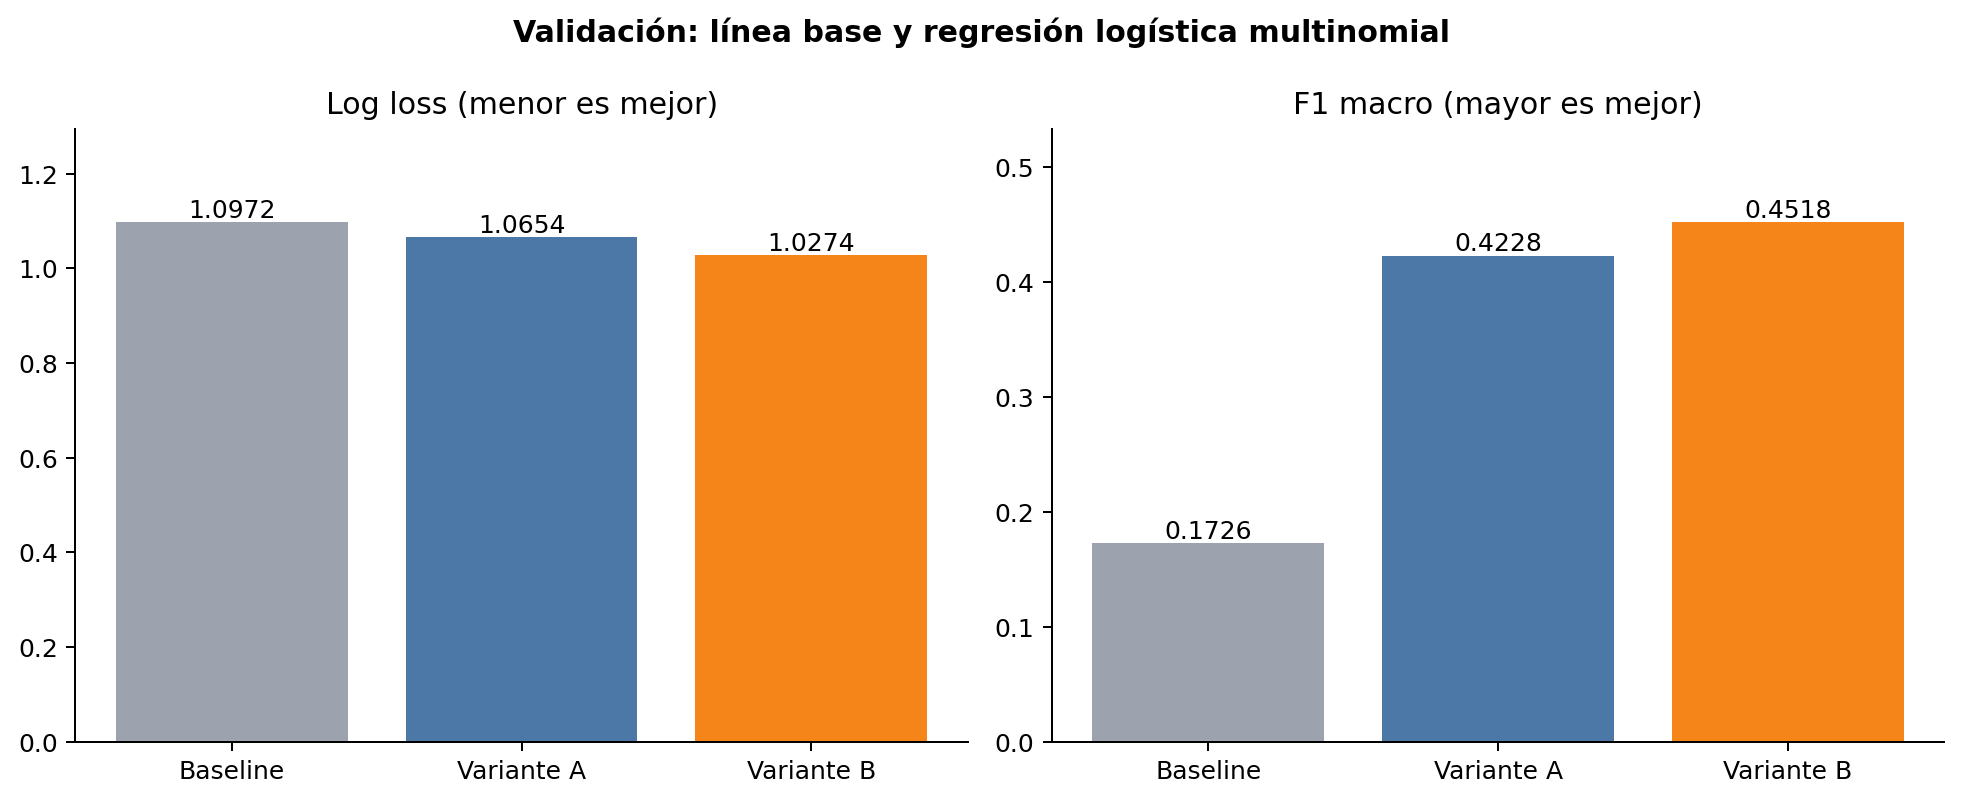

In [6]:
def metrics_table(split_key):
    labels = {'baseline': 'Baseline', 'variant_a': 'Variante A', 'variant_b': 'Variante B'}
    rows = []
    for key, label in labels.items():
        item = metrics[split_key][key]
        rows.append({
            'Modelo': label, 'Log loss': item['log_loss'],
            'F1 macro': item['f1_macro'], 'Accuracy': item['accuracy'],
            'Tiempo de entrenamiento': item['training_time_total_seconds'],
            'Tiempo de inferencia': item['inference_time_seconds'],
        })
    return pd.DataFrame(rows)

print('VALIDACIÓN')
display(metrics_table('validation_metrics'))
print('TEST FINAL')
display(metrics_table('test_metrics'))
print('Cambio B − A en validación:', metrics['validation_deltas_variant_b_minus_a'])
display(Image(filename=ROOT / 'docs/figures/logreg_comparacion_modelos.png'))

## 6. Análisis específicos: longitud, empates, coeficientes y posición

Los coeficientes pertenecen a variables estandarizadas. La regularización y la colinealidad entre caracteres, palabras, logaritmos y diferencias impiden interpretarlos como efectos independientes. La identidad de un modelo tampoco debe leerse como ranking absoluto o causal.

In [7]:
length = metrics['length_analysis_validation']
print(f"Respuesta más larga: EDA={length['eda_historical_longer_response_win_rate']:.2%}; validación={length['validation_longer_response_win_rate']:.2%}")
display(pd.DataFrame(length['groups']).T)

tie_test = metrics['test_metrics']['variant_b']['per_class']['tie']
print('Empate en test:', tie_test)
print('Matriz de confusión:', metrics['test_metrics']['variant_b']['confusion_matrix'])
print('Diagnóstico A/B:', metrics['swap_test'])

coefficients = pd.DataFrame(metrics['coefficient_analysis']['standardized_numeric_coefficients'])
display(coefficients[coefficients['feature'].isin(['numeric__dif_len', 'numeric__dif_words', 'numeric__dif_log_len'])])
display(pd.DataFrame(metrics['coefficient_analysis']['high_correlation_pairs_abs_ge_0_90']))

Respuesta más larga: EDA=61.63%; validación=62.15%


,n,observed_proportions,mean_predicted_probabilities,accuracy,log_loss
A más extensa (>10%),3670,"{'a': 0.44959128065395093, 'b': 0.255313351498...","{'a': 0.4270508700700903, 'b': 0.2639482396953...",0.494005,1.017601
similares (±10%),1243,"{'a': 0.32260659694288013, 'b': 0.293644408688...","{'a': 0.3534433963108204, 'b': 0.3294698703117...",0.437651,1.053081
B más extensa (>10%),3700,"{'a': 0.2591891891891892, 'b': 0.4443243243243...","{'a': 0.26514306640861407, 'b': 0.430966518664...",0.481622,1.028538


Empate en test: {'label': 2, 'name': 'Empate', 'precision': 0.4081020255063766, 'recall': 0.20474219044034625, 'f1': 0.27268170426065164, 'support': 2657}
Matriz de confusión: [[1815, 806, 388], [791, 1755, 401], [1116, 997, 544]]
Diagnóstico A/B: {'mean_absolute_errors': {'p_a_original_vs_p_b_swapped': 0.030543783265822164, 'p_b_original_vs_p_a_swapped': 0.030618442957617956, 'p_tie_original_vs_p_tie_swapped': 0.027359708996138724}, 'aggregate_mae': 0.029507311739859616, 'consistency_score_1_minus_mae': 0.9704926882601403, 'n_observations': 8613}


,class,class_name,feature,coefficient
7,0,Gana A,numeric__dif_len,0.049603
8,0,Gana A,numeric__dif_words,0.063212
12,0,Gana A,numeric__dif_log_len,0.103498
20,1,Gana B,numeric__dif_len,-0.052155
21,1,Gana B,numeric__dif_words,-0.057345
25,1,Gana B,numeric__dif_log_len,-0.107632
33,2,Empate,numeric__dif_len,0.002552
34,2,Empate,numeric__dif_words,-0.005867
38,2,Empate,numeric__dif_log_len,0.004133


,feature_1,feature_2,correlation
0,prompt_len,prompt_words,0.965616
1,resp_a_len,resp_a_words,0.988632
2,resp_b_len,resp_b_words,0.984671
3,dif_len,dif_words,0.975962


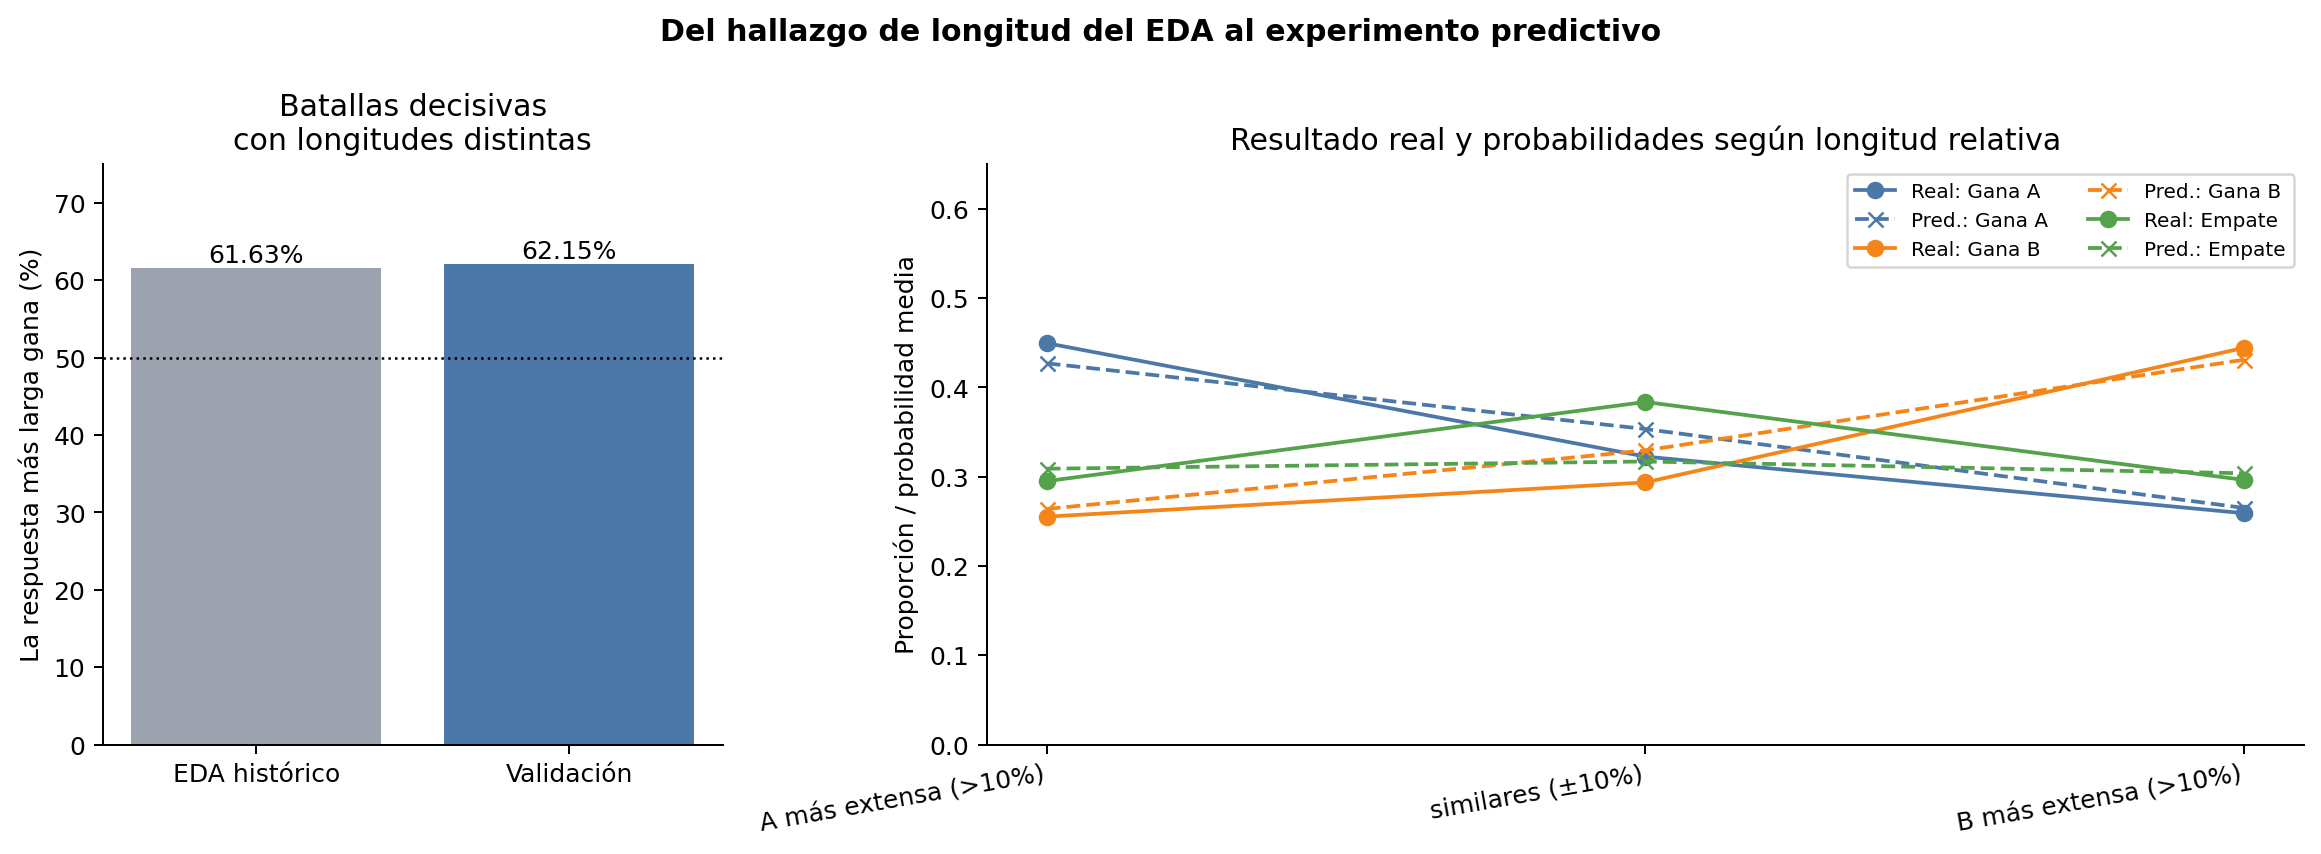

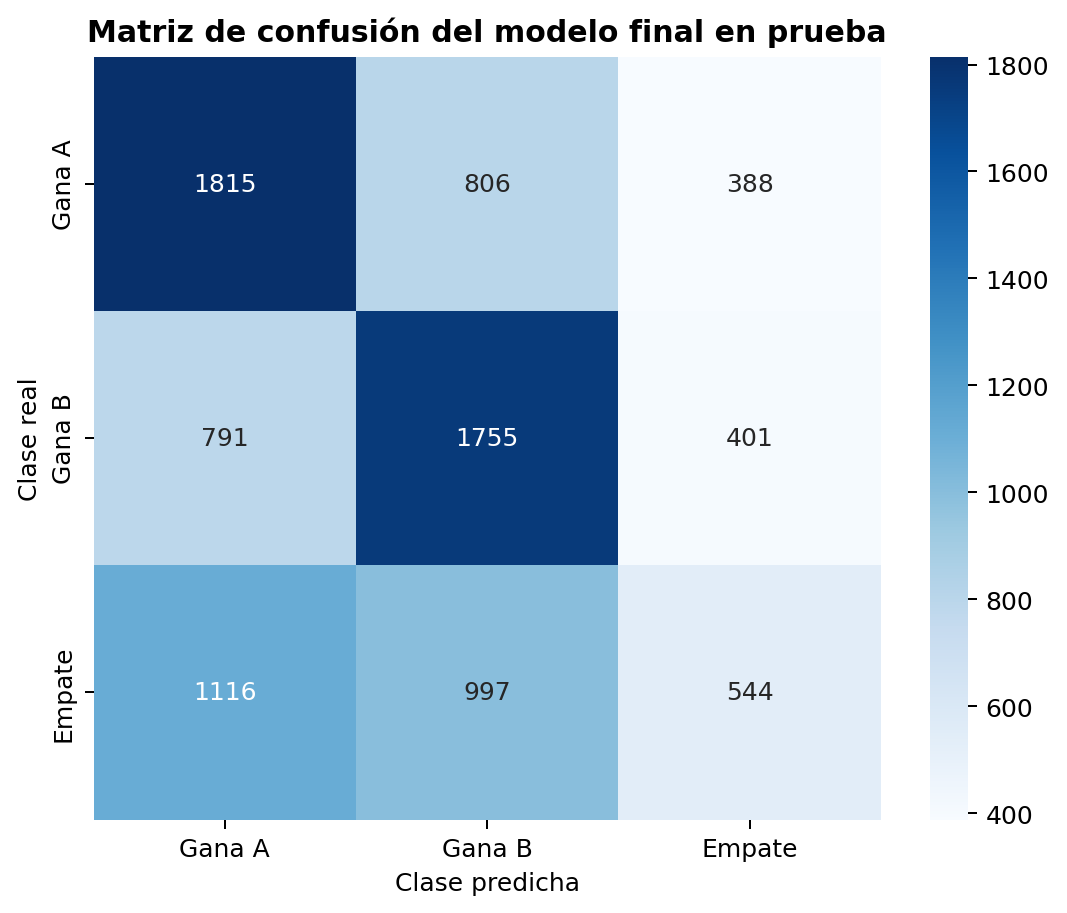

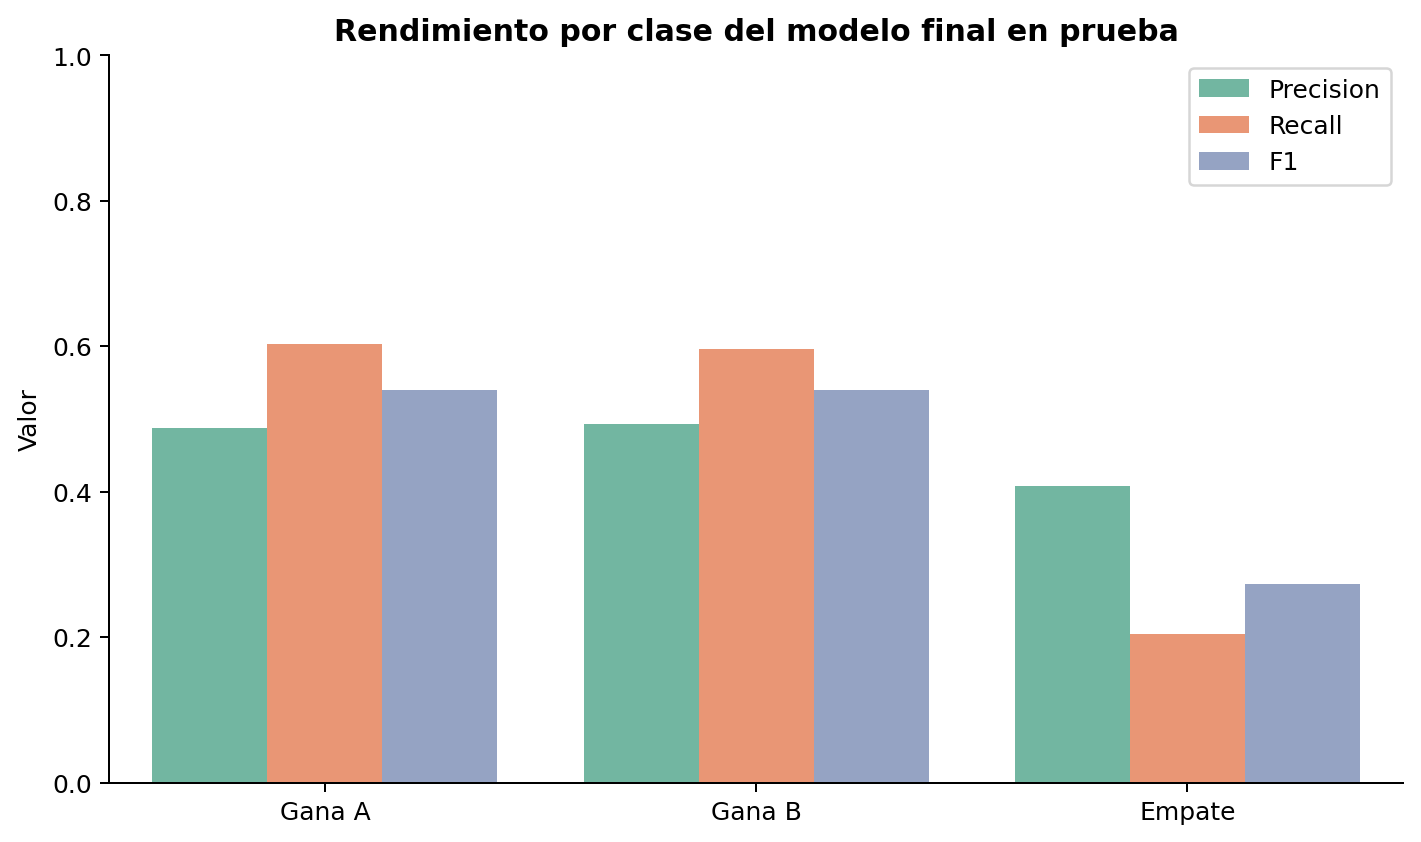

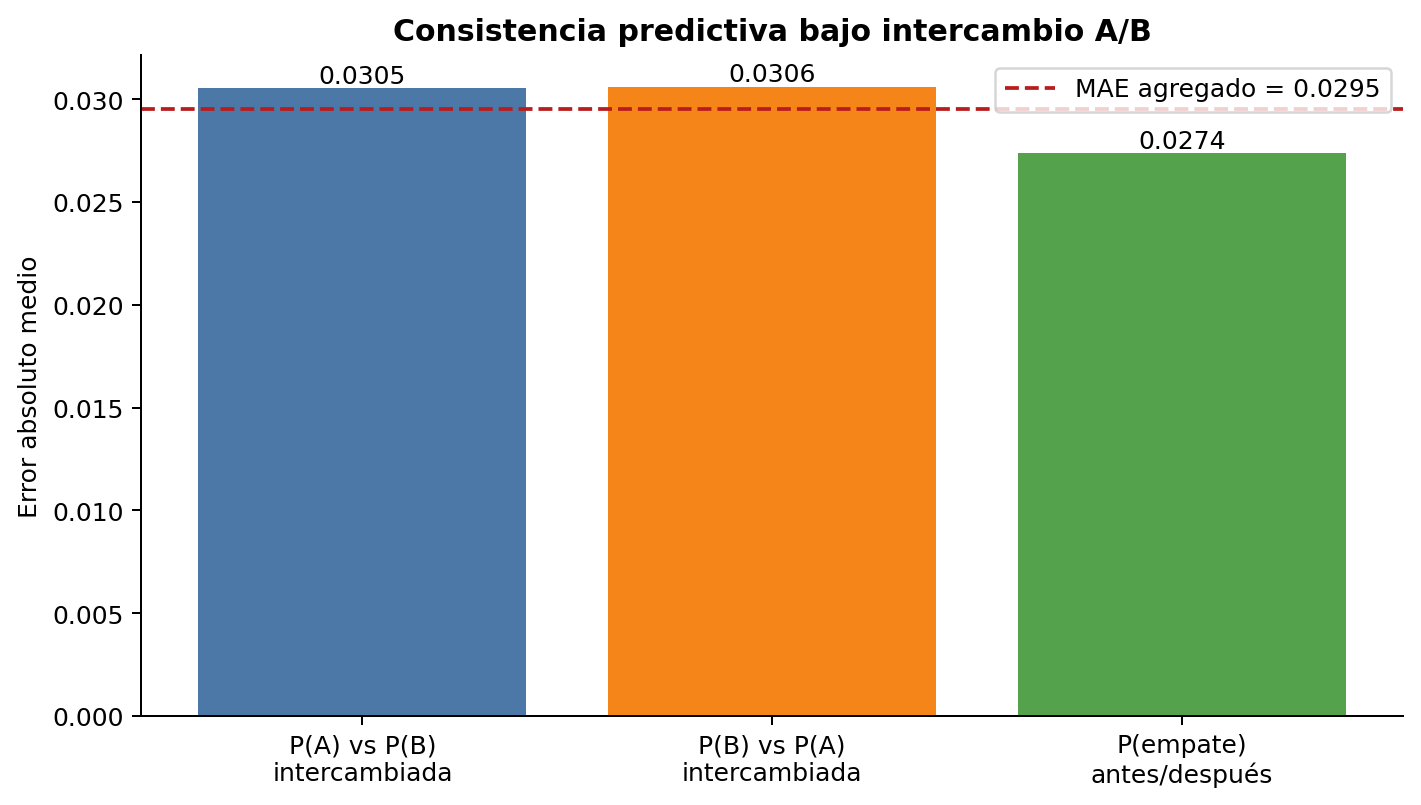

In [8]:
for filename in [
    'logreg_longitud_validacion.png',
    'logreg_matriz_confusion.png',
    'logreg_rendimiento_clases.png',
    'logreg_consistencia_ab.png',
]:
    display(Image(filename=ROOT / 'docs' / 'figures' / filename))

## 7. Conclusiones de las hipótesis

| Hipótesis | Conclusión | Evidencia |
|---|---|---|
| H1 | **Respaldada** | A supera el baseline; 62.15 % de victorias de la respuesta más larga en validación y signos coherentes en las diferencias. |
| H2 | **Respaldada** | B reduce 0.0380 el log loss y aumenta 0.0290 F1 macro y 0.0298 accuracy frente a A. |
| H3 | **Respaldada** | Recall de empate 0.2047 y F1 0.2727 en test, inferiores a A/B; 2,113 empates se confunden con victorias. |
| H4 | **Respaldada con efecto pequeño** | MAE agregado A/B de 0.0295 y consistencia 0.9705: alta estabilidad, no simetría exacta. |
| H5 | **Respaldada** | B mejora el baseline, pero accuracy 0.4777 y el bajo recall de empate muestran límites tabulares. No se anticipa el resultado de modelos semánticos. |

La asociación entre extensión y voto no implica causalidad ni permite afirmar que una respuesta extensa sea mejor. La prueba A/B diagnostica consistencia predictiva, no demuestra sesgo causal.

## 8. Artefactos e inferencia reutilizable

La Variante B genera `results/preds/logreg_val.csv`, `results/preds/logreg_test.csv`, `results/metrics/logreg.json` y `models/logreg_pipeline.joblib`. El binario se excluye de Git y puede regenerarse. Las probabilidades recuperadas tras serializar fueron idénticas (diferencia máxima 0.0).

In [9]:
pipeline_path = ROOT / metrics['artifacts']['pipeline']
pipeline = joblib.load(pipeline_path)
example = predict_single(
    pipeline,
    prompt='Explica brevemente qué es la regularización L2.',
    response_a='La regularización L2 penaliza coeficientes grandes mediante su suma de cuadrados.',
    response_b='Es una técnica que reduce el sobreajuste.',
    model_a='modelo-no-visto-a',
    model_b='modelo-no-visto-b',
)
print(example, 'suma =', sum(example.values()))

{'p_a': 0.31175462352643984, 'p_b': 0.2470304908964517, 'p_tie': 0.4412148855771085}

 suma = 1.0


## Referencias

Böhning, D. (1992). Multinomial logistic regression algorithm. *Annals of the Institute of Statistical Mathematics, 44*(1), 197–200. https://doi.org/10.1007/BF00048682

Chiang, W.-L., et al. (2024). Chatbot Arena: An open platform for evaluating LLMs by human preference. *Proceedings of the 41st International Conference on Machine Learning, 235*, 8359–8388. https://proceedings.mlr.press/v235/chiang24b.html

El desarrollo narrativo completo y la sección lista para el informe grupal están en `docs/modelo_regresion_logistica.md`.